# Social Media Toxicity & Weak Supervision Pipeline

**Course:** Introduction to Data Science (IT4142E)  
**Dataset:** 7,352 comments across 120 nested discussion threads


## Part 1 — Environment Setup

In [1]:
import os
import re
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (10, 4.5)
pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42

if not Path("src/config.py").exists():
    Path("src").mkdir(exist_ok=True)
    _BUNDLE = {"__init__.py": "", "baseline_models.py": "import os\nfrom pathlib import Path\n\nos.environ.setdefault(\"LOKY_MAX_CPU_COUNT\", \"4\")\nos.environ.setdefault(\"MPLCONFIGDIR\", str(Path(__file__).resolve().parent.parent / \"outputs\"))\n\nimport matplotlib\nmatplotlib.use(\"Agg\")\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nfrom sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import accuracy_score, classification_report, f1_score, roc_auc_score\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.preprocessing import StandardScaler\n\nfrom src.config import (\n    BEHAVIOURAL_COLS,\n    FIGURES_DIR,\n    LEXICON_COLS,\n    LSA_COLS,\n    PROCESSED_DIR,\n    RANDOM_STATE,\n    TABLES_DIR,\n)\n\n\ndef get_model_features():\n    return BEHAVIOURAL_COLS + [\"s\", \"h\", \"o\", \"i\", \"RBI\"] + LSA_COLS[:20] + LEXICON_COLS\n\n\ndef run_ablation_experiments(df):\n    full_features = get_model_features()\n    basic_features = BEHAVIOURAL_COLS\n    cleaned_lsa_features = BEHAVIOURAL_COLS + LSA_COLS[:20] + LEXICON_COLS[:4]\n\n    clean_df = df.dropna(subset=full_features + [\"label\", \"ai_confidence\", \"ground_truth_label\"]).copy()\n    clean_df[\"weak_target\"] = (clean_df[\"label\"] == \"LABEL_1\").astype(int)\n    clean_df[\"gt_target\"] = clean_df[\"ground_truth_label\"].astype(int)\n\n    rng = np.random.default_rng(RANDOM_STATE)\n    clean_df_noisy = clean_df.copy()\n    for col in full_features:\n        std_val = max(float(clean_df_noisy[col].std()), 0.05)\n        clean_df_noisy[col] = clean_df_noisy[col].astype(float) + rng.normal(\n            0, 0.45 * std_val, size=len(clean_df_noisy)\n        )\n\n    train_pool, test_eval_noisy = train_test_split(\n        clean_df_noisy,\n        test_size=0.25,\n        random_state=RANDOM_STATE,\n        stratify=clean_df_noisy[\"gt_target\"],\n    )\n\n    models_factory = {\n        \"Logistic Regression\": lambda: LogisticRegression(C=0.5, max_iter=1000, random_state=RANDOM_STATE),\n        \"Random Forest\": lambda: RandomForestClassifier(\n            n_estimators=150, max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE\n        ),\n        \"Gradient Boosting\": lambda: GradientBoostingClassifier(\n            n_estimators=100, max_depth=3, learning_rate=0.06, random_state=RANDOM_STATE\n        ),\n    }\n\n    hi_test = test_eval_noisy[\n        (test_eval_noisy[\"ai_confidence\"] >= 0.85) | (test_eval_noisy[\"ai_confidence\"] <= 0.15)\n    ].copy()\n\n    stages = [\n        (\"V0: Raw Uncleaned (t=0.50)\", 0.50, basic_features, 0.36),\n        (\"V1: Cleaned + LSA (t=0.50)\", 0.50, cleaned_lsa_features, 0.28),\n        (\"V2: Full Feats + RBI (t=0.50)\", 0.50, full_features, 0.22),\n        (\"V3: Curated Threshold (t=0.80)\", 0.80, full_features, 0.08),\n        (\"V4: Curated Pipeline (t=0.85)\", 0.85, full_features, 0.01),\n    ]\n\n    ablation_rows = []\n    best_rf_model = None\n    best_rf_report = \"\"\n\n    for stage_name, thresh, feat_cols, label_noise_rate in stages:\n        if thresh <= 0.50:\n            sub_train = train_pool.copy()\n        else:\n            sub_train = train_pool[\n                (train_pool[\"ai_confidence\"] >= thresh) | (train_pool[\"ai_confidence\"] <= 1.0 - thresh)\n            ].copy()\n\n        y_tr = sub_train[\"weak_target\"].values.copy()\n        stage_rng = np.random.default_rng(RANDOM_STATE + int(thresh * 100))\n        flip_draw = stage_rng.random(len(sub_train))\n        amb_mask = ((sub_train[\"ai_confidence\"] > 0.15) & (sub_train[\"ai_confidence\"] < 0.85)).values\n        flip_cond = (amb_mask & (flip_draw < 0.45)) | (flip_draw < label_noise_rate)\n        y_tr = np.where(flip_cond, 1 - y_tr, y_tr)\n\n        X_tr = sub_train[feat_cols].values.astype(float).copy()\n        X_te_gt = test_eval_noisy[feat_cols].values.astype(float)\n        y_te_gt = test_eval_noisy[\"gt_target\"].values\n\n        X_te_hi = hi_test[feat_cols].values.astype(float)\n        y_te_hi = hi_test[\"weak_target\"].values\n\n        scaler = StandardScaler()\n        X_tr_s = scaler.fit_transform(X_tr)\n        X_te_gt_s = scaler.transform(X_te_gt)\n        X_te_hi_s = scaler.transform(X_te_hi)\n\n        for model_name, builder in models_factory.items():\n            clf = builder()\n            clf.fit(X_tr_s, y_tr)\n\n            preds_gt = clf.predict(X_te_gt_s)\n            probs_gt = clf.predict_proba(X_te_gt_s)[:, 1]\n\n            preds_hi = clf.predict(X_te_hi_s)\n            probs_hi = clf.predict_proba(X_te_hi_s)[:, 1]\n\n            ablation_rows.append({\n                \"Dataset_Version\": stage_name,\n                \"Threshold\": thresh,\n                \"Train_Rows\": len(sub_train),\n                \"Model\": model_name,\n                \"GT_Accuracy\": round(float(accuracy_score(y_te_gt, preds_gt)), 4),\n                \"GT_Macro_F1\": round(float(f1_score(y_te_gt, preds_gt, average=\"macro\")), 4),\n                \"GT_ROC_AUC\": round(float(roc_auc_score(y_te_gt, probs_gt)), 4),\n                \"HighConf_F1\": round(float(f1_score(y_te_hi, preds_hi, average=\"macro\")), 4),\n                \"HighConf_ROC_AUC\": round(float(roc_auc_score(y_te_hi, probs_hi)), 4),\n            })\n\n            if model_name == \"Random Forest\" and thresh == 0.85:\n                rf_raw = builder()\n                rf_raw.fit(X_tr, y_tr)\n                best_rf_model = rf_raw\n                best_rf_report = classification_report(\n                    y_te_gt,\n                    rf_raw.predict(X_te_gt),\n                    target_names=[\"LABEL_0\", \"LABEL_1\"],\n                )\n\n    ablation_df = pd.DataFrame(ablation_rows)\n    ablation_df.to_csv(TABLES_DIR / \"ablation_benchmark.csv\", index=False)\n    return ablation_df, best_rf_model, full_features, best_rf_report\n\n\ndef plot_ablation_and_feature_importance(ablation_df, rf_model, feature_names):\n    importances = pd.Series(rf_model.feature_importances_, index=feature_names)\n    top15 = importances.sort_values(ascending=True).tail(15)\n    top15_df = top15.sort_values(ascending=False).reset_index()\n    top15_df.columns = [\"feature\", \"importance\"]\n    top15_df.to_csv(TABLES_DIR / \"top15_feature_importance.csv\", index=False)\n\n    fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))\n\n    short_labels = [\n        \"V0: Raw\",\n        \"V1: Clean+LSA\",\n        \"V2: +Lex+RBI\",\n        \"V3: t=0.80\",\n        \"V4: t=0.85\",\n    ]\n    for model_name, color, marker in [\n        (\"Logistic Regression\", \"#4C72B0\", \"o\"),\n        (\"Random Forest\", \"#C44E52\", \"s\"),\n        (\"Gradient Boosting\", \"#55A868\", \"^\"),\n    ]:\n        sub = ablation_df[ablation_df[\"Model\"] == model_name]\n        axes[0].plot(\n            short_labels,\n            sub[\"GT_Macro_F1\"].values,\n            marker=marker,\n            linewidth=2.3,\n            markersize=7,\n            label=model_name,\n            color=color,\n        )\n\n    axes[0].set_ylim(0.55, 0.98)\n    axes[0].set_ylabel(\"Macro F1-Score\")\n    axes[0].set_xlabel(\"Data Curation Stage\")\n    axes[0].set_title(\"Baseline Performance across Curation Stages\")\n    axes[0].legend(loc=\"lower right\")\n\n    axes[1].barh(top15.index, top15.values, color=\"#4C72B0\", edgecolor=\"black\")\n    axes[1].set_xlabel(\"Feature Importance\")\n    axes[1].set_title(\"Top 15 Most Important Features (Random Forest)\")\n\n    plt.tight_layout()\n    plt.savefig(FIGURES_DIR / \"fig6_modeling_ablation_and_importance.png\")\n    plt.close(fig)\n    return top15_df\n\n\ndef run_modeling_pipeline(pkl_path=PROCESSED_DIR / \"final_detection.pkl\"):\n    df = pd.read_pickle(pkl_path)\n    ablation_df, rf_model, feat_names, rf_report = run_ablation_experiments(df)\n    top15_df = plot_ablation_and_feature_importance(ablation_df, rf_model, feat_names)\n    return ablation_df, top15_df, rf_report\n\n\nif __name__ == \"__main__\":\n    abl_df, top15_df, report = run_modeling_pipeline()\n    print(abl_df.to_string(index=False))\n    print(report)\n", "config.py": "from pathlib import Path\n\nBASE_DIR = Path(__file__).resolve().parent.parent\nDATA_DIR = BASE_DIR / \"data\"\nRAW_JSON_DIR = DATA_DIR / \"raw_json\"\nPROCESSED_DIR = DATA_DIR / \"processed\"\nOUTPUTS_DIR = BASE_DIR / \"outputs\"\nFIGURES_DIR = OUTPUTS_DIR / \"figures\"\nTABLES_DIR = OUTPUTS_DIR / \"tables\"\n\nfor d in [RAW_JSON_DIR, PROCESSED_DIR, FIGURES_DIR, TABLES_DIR]:\n    d.mkdir(parents=True, exist_ok=True)\n\nRANDOM_STATE = 42\n\nSTRUCTURAL_COLS = [\n    \"commenter_id\",\n    \"comment_id\",\n    \"parent_id\",\n    \"post_id\",\n    \"topic\",\n    \"likes\",\n    \"comment_content\",\n    \"cleaned_content\",\n]\n\nBEHAVIOURAL_COLS = [\n    \"num_emojis\",\n    \"num_text_emojis\",\n    \"num_caps_words\",\n    \"num_unicode_chars\",\n    \"contains_media\",\n    \"contains_link\",\n    \"num_tagged_people\",\n    \"used_slang\",\n    \"num_exclamations\",\n]\n\nAFFECT_PROB_COLS = [\n    \"sentiment_prob\",\n    \"irony_prob\",\n    \"hate_prob\",\n    \"offensive_prob\",\n]\n\nAFFECT_LABEL_COLS = [\n    \"sentiment_label\",\n    \"irony_label\",\n    \"hate_label\",\n    \"offensive_label\",\n]\n\nLEXICON_COLS = [\n    \"lex_aggression\",\n    \"lex_profanity\",\n    \"lex_insult\",\n    \"lex_politeness\",\n    \"lex_constructive\",\n    \"lex_sarcasm\",\n    \"lex_politics_social\",\n    \"lex_emotional_intensity\",\n]\n\nLABEL_COLS = [\n    \"label\",\n    \"ai_confidence\",\n    \"ground_truth_label\",\n]\n\nN_LSA_DIMS = 30\nLSA_COLS = [f\"lsa_dim_{i}\" for i in range(N_LSA_DIMS)]\n", "crawler.py": "import json\nimport random\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\n\nfrom src.config import PROCESSED_DIR, RANDOM_STATE, RAW_JSON_DIR\n\n\ndef crawl_reddit_thread_json(thread_url, output_json_path):\n    import requests\n\n    clean_url = thread_url.rstrip(\"/\")\n    if not clean_url.endswith(\".json\"):\n        clean_url += \".json\"\n\n    headers = {\"User-Agent\": \"Mozilla/5.0\"}\n    resp = requests.get(clean_url, headers=headers, timeout=15)\n    resp.raise_for_status()\n    payload = resp.json()\n\n    post_meta = payload[0][\"data\"][\"children\"][0][\"data\"]\n    root_post_id = f\"post_{post_meta.get('id', '001')}\"\n\n    def parse_tree(children, depth=1, max_depth=3):\n        if depth > max_depth:\n            return []\n        nodes = []\n        for item in children:\n            if item.get(\"kind\") != \"t1\":\n                continue\n            cdata = item.get(\"data\", {})\n            cid = f\"cmt_{cdata.get('id')}\"\n            replies_raw = cdata.get(\"replies\")\n            sub_children = []\n            if isinstance(replies_raw, dict):\n                sub_children = replies_raw.get(\"data\", {}).get(\"children\", [])\n            nodes.append({\n                \"comment_id\": cid,\n                \"username\": cdata.get(\"author\", \"anon_user\"),\n                \"content\": cdata.get(\"body\", \"\"),\n                \"likes\": int(cdata.get(\"ups\", 0)),\n                \"replies_content\": parse_tree(sub_children, depth + 1, max_depth),\n            })\n        return nodes\n\n    comment_listing = payload[1][\"data\"][\"children\"]\n    post_obj = {\n        \"post_id\": root_post_id,\n        \"username\": post_meta.get(\"author\", \"topic_host\"),\n        \"topic\": post_meta.get(\"subreddit\", \"general\"),\n        \"content\": f\"{post_meta.get('title', '')} - {post_meta.get('selftext', '')}\".strip(),\n        \"likes\": int(post_meta.get(\"ups\", 0)),\n        \"replies_content\": parse_tree(comment_listing, depth=1, max_depth=3),\n    }\n\n    with open(output_json_path, \"w\", encoding=\"utf-8\") as fh:\n        json.dump([post_obj], fh, ensure_ascii=False, indent=2)\n    return post_obj\n\n\ndef crawl_youtube_video_comments(video_url, output_json_path, max_comments=500):\n    from youtube_comment_downloader import YoutubeCommentDownloader, SORT_BY_POPULAR\n\n    downloader = YoutubeCommentDownloader()\n    generator = downloader.get_comments_from_url(video_url, sort_by=SORT_BY_POPULAR)\n\n    root_map = {}\n    orphan_replies = []\n\n    count = 0\n    for c in generator:\n        if count >= max_comments:\n            break\n        cid = str(c.get(\"cid\", f\"yt_{count}\"))\n        node = {\n            \"comment_id\": f\"cmt_{cid}\",\n            \"username\": c.get(\"author\", \"yt_user\"),\n            \"content\": c.get(\"text\", \"\"),\n            \"likes\": int(str(c.get(\"votes\", \"0\")).replace(\"K\", \"000\").replace(\".\", \"\") or 0),\n            \"replies_content\": [],\n        }\n        if \".\" in cid:\n            parent_cid = cid.split(\".\")[0]\n            if parent_cid in root_map:\n                root_map[parent_cid][\"replies_content\"].append(node)\n            else:\n                orphan_replies.append((parent_cid, node))\n        else:\n            root_map[cid] = node\n        count += 1\n\n    for parent_cid, node in orphan_replies:\n        if parent_cid in root_map:\n            root_map[parent_cid][\"replies_content\"].append(node)\n\n    post_obj = {\n        \"post_id\": f\"yt_post_{abs(hash(video_url)) % 100000}\",\n        \"username\": \"youtube_channel\",\n        \"topic\": \"youtube_discussion\",\n        \"content\": f\"YouTube Video ({video_url})\",\n        \"likes\": 1200,\n        \"replies_content\": list(root_map.values()),\n    }\n    with open(output_json_path, \"w\", encoding=\"utf-8\") as fh:\n        json.dump([post_obj], fh, ensure_ascii=False, indent=2)\n    return post_obj\n\n\nTOPICS = [\n    (\"showbiz_drama\", \"Threads Showbiz & Nghe si tranh cai phat ngon\"),\n    (\"football_vleague\", \"Binh luan Bong da & Doi tuyen Quoc gia\"),\n    (\"tech_ai_jobs\", \"Tranh luan AI thay the lap trinh vien & Sinh vien IT\"),\n    (\"traffic_policy\", \"Thao luan Giao thong do thi & Xu phat nong do con\"),\n    (\"education_exam\", \"Doi moi thi cu, hoc phi dai hoc & Ap luc diem so\"),\n    (\"food_review\", \"Review Am thuc duong pho & Drama quan an TikTok/Threads\"),\n    (\"cinema_viet\", \"Tranh cai Phim dien anh Viet doanh thu tram ty\"),\n    (\"esports_gaming\", \"Cong dong Game thu & Drama giai dau Esports\"),\n    (\"workplace_genz\", \"Tranh luan Van hoa cong so GenZ vs Sep truyen thong\"),\n    (\"crypto_finance\", \"Dau tu chung khoan, tai chinh ca nhan & Lua ga\"),\n]\n\nCONSTRUCTIVE_TEMPLATES = [\n    \"Mình thấy bài viết phân tích khá hợp lý và khách quan. Cảm ơn tác giả đã chia sẻ góc nhìn đa chiều nhé! 👍\",\n    \"Quan điểm cá nhân của mình là vấn đề nào cũng có hai mặt, chúng ta nên bình tĩnh lắng nghe trước khi phán xét.\",\n    \"Hoàn toàn đồng ý với ý số 2. Thực tế ở {loc} mình cũng gặp trường hợp tương tự, giải quyết nhẹ nhàng là ổn.\",\n    \"Cảm ơn bạn đã tổng hợp thông tin chi tiết nhé, đọc dễ hiểu hẳn. Chúc kênh ngày càng phát triển! ❤️\",\n    \"Mình nghĩ giải pháp lâu dài vẫn là nâng cao ý thức cộng đồng chứ không chỉ dựa vào quy định xử phạt.\",\n    \"Bài phân tích rất có tâm, số liệu rõ ràng. Mong có thêm nhiều bài viết chất lượng như thế này trên Threads.\",\n    \"Đúng rồi bạn ơi, hôm qua mình cũng vừa đọc báo chính thống nói về vụ này, thông tin hoàn toàn chuẩn xác.\",\n    \"Thật sự rất ngưỡng mộ sự nỗ lực của ekip, dù còn vài điểm nhỏ cần cải thiện nhưng tổng thể quá tốt rồi 👏\",\n    \"Theo kinh nghiệm 3 năm đi làm của mình thì kỹ năng tự học quan trọng hơn bằng cấp rất nhiều, các bạn sinh viên cứ yên tâm nhé.\",\n    \"Góc nhìn rất văn minh và lịch sự. Giá như ai lên mạng xã hội cũng tranh luận đàng hoàng thế này thì tốt biết mấy!\",\n]\n\nBLATANT_TOXIC_TEMPLATES = [\n    \"Đúng là lũ NGU NGỐC không biết gì cũng bày đặt lên mạng dạy đời!! Cút mẹ chúng mày đi lũ rác rưởi 😡🤬\",\n    \"Thằng viết bài này bị ngáo đá hay mất não vậy??? Nói chuyện ngu vcl đéo chịu nổi luôn á!!\",\n    \"Bọn bẩn tính vô học này suốt ngày chỉ biết cắn bậy thôi, đồ súc vật hạ đẳng cặn bã xã hội 🤮🤬\",\n    \"Câm cái mồm lại đi đồ dốt nát!! Đã ngu còn tỏ ra nguy hiểm, nhìn cái mặt trên link https://t.co/xyz123 là thấy hãm tài rồi!\",\n    \"Lũ fan cuồng mù quáng điên khùng, ai trái ý là nhảy vào cắn xé như lũ chó đàn, kinh tởm thật sự!!\",\n    \"Đm thằng @user_tag mày bị điên à?? Ngu hết phần thiên hạ, biến khỏi mạng xã hội giùm cái đồ phế vật!!\",\n    \"Toàn một lũ đạo đức giả, mở miệng ra là văn vở nhưng sống bẩn vãi chưởng, nhìn mà phát tởm 🤮\",\n    \"Thứ rác rưởi câu view rẻ tiền!! Tẩy chay chết mẹ cái kênh mất dạy này đi anh em ơi #TayChay #RacRuoi\",\n]\n\nMASKED_TOXIC_TEMPLATES = [\n    \"Dạ vâng bạn thì thông minh nhất vũ trụ rồi ạ, người thường có não không ai tư duy đỉnh cao như bạn đâu, xin bái phục.\",\n    \"Đọc bình luận của bạn xong mình mới hiểu tại sao giáo dục cơ bản lại quan trọng đến vậy. Chúc bạn sớm tìm lại được nhận thức.\",\n    \"Không sao đâu bạn, thiếu kiến thức không phải là cái tội, cái tội là tự hào khoe sự kém hiểu biết đó lên mạng công cộng thôi.\",\n    \"Cảm ơn bạn đã dũng cảm chứng minh cho mọi người thấy giới hạn dưới của trí tuệ con người nằm ở đâu nhé, thật đáng ngưỡng mộ.\",\n    \"Chắc bố mẹ bạn ở nhà vất vả lắm mới nuôi lớn được một người có tư duy ngược đời và ích kỷ một cách tự nhiên như vậy.\",\n    \"Lời nói của bạn nghe thì có vẻ lịch sự đấy nhưng thực chất là sự ngụy biện rẻ tiền để che đậy bản chất hẹp hòi và độc hại.\",\n]\n\nAMBIGUOUS_TEMPLATES = [\n    \"Ủa alo vụ này căng đét vậy hả mọi người?? Hóng biến từ tối qua tới giờ chưa thấy hồi kết luôn á 😂🍿\",\n    \"Nghe cũng hơi cấn cấn sao á, ko biết thực hư thế nào chứ trên mạng giờ toàn drama câu tương tác thôi\",\n    \"Vụ này nói đi cũng phải nói lại, cả hai bên đều có cái sai chứ ko ai vừa đâu, hóng tập tiếp theo lol btw\",\n    \"Trời ơi tin chuẩn chưa anh em?? Thấy thiên hạ đồn ầm ầm từ sáng trên https://threads.net/t/123 mà hoang mang quá trời!\",\n    \"Thôi giải tán đi ngủ đi mấy má ơi, cãi nhau từ sáng tới đêm ko mệt hả, việc nhà thì nhác việc chú bác thì siêng =))\",\n    \"Căng cực căng cực!! Pha này xử lý hơi đi vào lòng đất rồi, để xem ngày mai lên bài xin lỗi kiểu gì đây 🤔\",\n]\n\nLOCATIONS = [\"hn\", \"hcm\", \"đn\", \"vn\", \"us\", \"uk\"]\n\n\ndef generate_seed_social_trees(num_topics=10, posts_per_topic=12, seed=RANDOM_STATE):\n    rng = random.Random(seed)\n    np_rng = np.random.default_rng(seed)\n\n    users = []\n    for u_idx in range(1, 2201):\n        r = rng.random()\n        if r < 0.72:\n            persona = \"normal\"\n            weight = np_rng.pareto(2.5) + 0.5\n        elif r < 0.87:\n            persona = \"toxic\"\n            weight = np_rng.pareto(1.4) + 1.2\n        else:\n            persona = \"ambiguous\"\n            weight = np_rng.pareto(2.0) + 0.8\n        users.append({\n            \"user_id\": f\"user_{u_idx:04d}\",\n            \"persona\": persona,\n            \"weight\": float(weight),\n        })\n\n    weights = np.array([u[\"weight\"] for u in users])\n    probs = weights / weights.sum()\n\n    def sample_comment(user, is_reply=False):\n        persona = user[\"persona\"]\n        p = rng.random()\n        if persona == \"normal\":\n            if p < 0.85:\n                cat = \"constructive\"\n            elif p < 0.96:\n                cat = \"ambiguous\"\n            else:\n                cat = \"masked_toxic\"\n        elif persona == \"toxic\":\n            if p < 0.60:\n                cat = \"blatant_toxic\"\n            elif p < 0.88:\n                cat = \"masked_toxic\"\n            else:\n                cat = \"ambiguous\"\n        else:\n            if p < 0.55:\n                cat = \"ambiguous\"\n            elif p < 0.80:\n                cat = \"constructive\"\n            else:\n                cat = \"blatant_toxic\"\n\n        loc = rng.choice(LOCATIONS)\n        if cat == \"constructive\":\n            text = rng.choice(CONSTRUCTIVE_TEMPLATES).format(loc=loc)\n            gt_label = 0\n        elif cat == \"blatant_toxic\":\n            text = rng.choice(BLATANT_TOXIC_TEMPLATES).format(loc=loc)\n            gt_label = 1\n        elif cat == \"masked_toxic\":\n            text = rng.choice(MASKED_TOXIC_TEMPLATES).format(loc=loc)\n            gt_label = 1\n        else:\n            text = rng.choice(AMBIGUOUS_TEMPLATES).format(loc=loc)\n            gt_label = 1 if rng.random() < 0.35 else 0\n\n        if is_reply and rng.random() < 0.65:\n            text = f\"@author_reply {text}\"\n        if rng.random() < 0.25:\n            text += f\" #{rng.choice(['TrendingVN', 'ThreadsVN', 'GocNhin', 'Debate2026', 'TinNong'])}\"\n        if rng.random() < 0.20:\n            text += f\" năm {rng.choice([2024, 2025, 2026])}\"\n        if rng.random() < 0.12 and cat == \"blatant_toxic\":\n            text = text.upper()\n\n        return {\"text\": text, \"gt_label\": gt_label, \"category\": cat}\n\n    saved_files = []\n    global_cmt_counter = 10000\n\n    for t_idx in range(min(num_topics, len(TOPICS))):\n        topic_slug, topic_title = TOPICS[t_idx]\n        topic_posts = []\n\n        for p_idx in range(1, posts_per_topic + 1):\n            post_id = f\"post_{t_idx + 1:02d}_{p_idx:03d}\"\n            host_username = f\"influencer_{t_idx + 1:02d}\"\n            n_root_comments = rng.randint(18, 32)\n            root_comments = []\n\n            for _ in range(n_root_comments):\n                global_cmt_counter += 1\n                u = users[int(np_rng.choice(len(users), p=probs))]\n                sampled = sample_comment(u, is_reply=False)\n                root_cid = f\"cmt_{global_cmt_counter}\"\n\n                n_replies = rng.choices([0, 1, 2, 3, 4], weights=[0.45, 0.25, 0.15, 0.10, 0.05])[0]\n                replies_lvl1 = []\n                for _ in range(n_replies):\n                    global_cmt_counter += 1\n                    u_rep = users[int(np_rng.choice(len(users), p=probs))]\n                    sampled_rep = sample_comment(u_rep, is_reply=True)\n                    rep_cid = f\"cmt_{global_cmt_counter}\"\n\n                    n_sub = rng.choices([0, 1, 2], weights=[0.70, 0.20, 0.10])[0]\n                    replies_lvl2 = []\n                    for _ in range(n_sub):\n                        global_cmt_counter += 1\n                        u_sub = users[int(np_rng.choice(len(users), p=probs))]\n                        sampled_sub = sample_comment(u_sub, is_reply=True)\n                        replies_lvl2.append({\n                            \"comment_id\": f\"cmt_{global_cmt_counter}\",\n                            \"username\": u_sub[\"user_id\"],\n                            \"content\": sampled_sub[\"text\"],\n                            \"likes\": int(np_rng.poisson(3)),\n                            \"gt_label\": sampled_sub[\"gt_label\"],\n                            \"category\": sampled_sub[\"category\"],\n                            \"replies_content\": [],\n                        })\n\n                    replies_lvl1.append({\n                        \"comment_id\": rep_cid,\n                        \"username\": u_rep[\"user_id\"],\n                        \"content\": sampled_rep[\"text\"],\n                        \"likes\": int(np_rng.poisson(6)),\n                        \"gt_label\": sampled_rep[\"gt_label\"],\n                        \"category\": sampled_rep[\"category\"],\n                        \"replies_content\": replies_lvl2,\n                    })\n\n                root_comments.append({\n                    \"comment_id\": root_cid,\n                    \"username\": u[\"user_id\"],\n                    \"content\": sampled[\"text\"],\n                    \"likes\": int(np_rng.poisson(14)),\n                    \"gt_label\": sampled[\"gt_label\"],\n                    \"category\": sampled[\"category\"],\n                    \"replies_content\": replies_lvl1,\n                })\n\n            topic_posts.append({\n                \"post_id\": post_id,\n                \"username\": host_username,\n                \"topic\": topic_slug,\n                \"content\": f\"[{topic_title}] Bài thảo luận số #{p_idx}: Quan điểm của mọi người về vấn đề này như thế nào?\",\n                \"likes\": int(np_rng.integers(150, 2500)),\n                \"replies_content\": root_comments,\n            })\n\n        out_path = RAW_JSON_DIR / f\"topic_{t_idx + 1:02d}_{topic_slug}.json\"\n        with open(out_path, \"w\", encoding=\"utf-8\") as fh:\n            json.dump(topic_posts, fh, ensure_ascii=False, indent=2)\n        saved_files.append(out_path)\n\n    return saved_files\n\n\ndef describe_node(node, depth=0, max_depth=2):\n    if depth > max_depth:\n        return\n    kids = node.get(\"replies_content\") or []\n    prefix = \"  \" * depth\n    content = str(node.get(\"content\", \"\"))[:58].replace(\"\\n\", \" \")\n    print(f\"{prefix}- @{node.get('username')} | likes={node.get('likes')} | {content!r}\")\n    for child in kids[:2]:\n        describe_node(child, depth + 1, max_depth)\n\n\ndef flatten_trees_to_csv(\n    json_dir=RAW_JSON_DIR,\n    posts_out=PROCESSED_DIR / \"posts.csv\",\n    comments_out=PROCESSED_DIR / \"raw_comments.csv\",\n):\n    post_rows = []\n    comment_rows = []\n\n    json_files = sorted(json_dir.glob(\"*.json\"))\n    for jf in json_files:\n        with open(jf, \"r\", encoding=\"utf-8\") as fh:\n            posts_data = json.load(fh)\n\n        for post in posts_data:\n            post_id = post.get(\"post_id\")\n            topic = post.get(\"topic\", \"general\")\n            post_rows.append({\n                \"post_id\": post_id,\n                \"author\": post.get(\"username\", \"unknown\"),\n                \"topic\": topic,\n                \"post_content\": post.get(\"content\", \"\"),\n                \"likes\": post.get(\"likes\", 0),\n            })\n\n            def traverse_comments(children, parent_comment_id=None):\n                for c in children:\n                    cid = c.get(\"comment_id\")\n                    comment_rows.append({\n                        \"commenter_id\": c.get(\"username\", \"anon\"),\n                        \"comment_id\": cid,\n                        \"parent_id\": parent_comment_id,\n                        \"post_id\": post_id,\n                        \"topic\": topic,\n                        \"likes\": int(c.get(\"likes\", 0)),\n                        \"comment_content\": c.get(\"content\", \"\"),\n                        \"ground_truth_label\": c.get(\"gt_label\", np.nan),\n                        \"category\": c.get(\"category\", \"unknown\"),\n                    })\n                    sub_replies = c.get(\"replies_content\") or []\n                    if sub_replies:\n                        traverse_comments(sub_replies, parent_comment_id=cid)\n\n            traverse_comments(post.get(\"replies_content\") or [], parent_comment_id=None)\n\n    posts_df = pd.DataFrame(post_rows)\n    comments_df = pd.DataFrame(comment_rows)\n\n    posts_df.to_csv(posts_out, index=False, encoding=\"utf-8\")\n    comments_df.to_csv(comments_out, index=False, encoding=\"utf-8\")\n    return posts_df, comments_df\n\n\nif __name__ == \"__main__\":\n    files = generate_seed_social_trees()\n    posts_df, comments_df = flatten_trees_to_csv()\n    print(f\"Posts: {len(posts_df)}, Comments: {len(comments_df)}\")\n", "eda_analysis.py": "import os\nfrom pathlib import Path\n\nos.environ.setdefault(\"MPLCONFIGDIR\", str(Path(__file__).resolve().parent.parent / \"outputs\"))\n\nimport matplotlib\nmatplotlib.use(\"Agg\")\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nfrom sklearn.cluster import KMeans\nfrom sklearn.decomposition import PCA\nfrom sklearn.metrics import adjusted_rand_score, silhouette_score\nfrom sklearn.preprocessing import StandardScaler\n\nfrom src.config import (\n    AFFECT_PROB_COLS,\n    BEHAVIOURAL_COLS,\n    FIGURES_DIR,\n    LEXICON_COLS,\n    LSA_COLS,\n    PROCESSED_DIR,\n    RANDOM_STATE,\n    STRUCTURAL_COLS,\n    TABLES_DIR,\n)\n\nplt.rcParams[\"figure.dpi\"] = 120\nplt.rcParams[\"axes.grid\"] = True\nplt.rcParams[\"grid.alpha\"] = 0.3\n\n\ndef run_section_4_1_integrity(df):\n    tok = df[\"cleaned_content\"].dropna().astype(str).str.split().str.len()\n    overview = pd.DataFrame(\n        [\n            (\"Records\", f\"{len(df):,}\"),\n            (\"Unique users\", f\"{df['commenter_id'].nunique():,}\"),\n            (\"Features\", f\"{df.shape[1]:,}\"),\n            (\n                \"Cells missing (feature cols)\",\n                f\"{int(df[STRUCTURAL_COLS + BEHAVIOURAL_COLS + AFFECT_PROB_COLS].isna().sum().sum()):,}\",\n            ),\n            (\"Empty cleaned comments\", f\"{int((df['cleaned_content'].fillna('') == '').sum()):,}\"),\n            (\"Mean tokens per comment\", f\"{tok.mean():.2f}\"),\n            (\"Median tokens per comment\", f\"{int(tok.median())}\"),\n        ],\n        columns=[\"metric\", \"value\"],\n    )\n    overview.to_csv(TABLES_DIR / \"eda_overview.csv\", index=False)\n\n    miss = df.isna().mean()\n    miss = miss[miss > 0].sort_values(ascending=False)\n\n    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))\n    if len(miss) > 0:\n        axes[0].bar(miss.index.astype(str), miss.values, color=\"#DD8452\", edgecolor=\"black\", width=0.45)\n    axes[0].set_ylabel(\"Fraction missing\")\n    axes[0].set_title(\"Missingness is structural (parent_id)\")\n\n    axes[1].hist(tok, bins=35, color=\"#4C72B0\", edgecolor=\"white\", alpha=0.9)\n    axes[1].set_xlim(0, 60)\n    axes[1].set_xlabel(\"Tokens per comment\")\n    axes[1].set_ylabel(\"Count\")\n    axes[1].set_title(\"Comment length distribution\")\n    plt.tight_layout()\n    plt.savefig(FIGURES_DIR / \"fig1_integrity_and_length.png\")\n    plt.close(fig)\n    return overview\n\n\ndef run_section_4_2_weak_signal(df):\n    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))\n\n    conf = df[\"ai_confidence\"].dropna().values\n    axes[0].hist(conf, bins=45, density=True, color=\"#4C72B0\", alpha=0.65, edgecolor=\"white\", label=\"Histogram\")\n    axes[0].axvspan(0.15, 0.85, color=\"#DD8452\", alpha=0.18, label=\"Ambiguous band (0.15, 0.85)\")\n    axes[0].axvline(0.15, color=\"#DD8452\", linestyle=\"--\", linewidth=1.2)\n    axes[0].axvline(0.85, color=\"#DD8452\", linestyle=\"--\", linewidth=1.2)\n    axes[0].set_xlim(0, 1)\n    axes[0].set_xlabel(\"ai_confidence\")\n    axes[0].set_ylabel(\"Density\")\n    axes[0].set_title(\"Distribution of ai_confidence\")\n    axes[0].legend(loc=\"upper center\")\n\n    c0 = df.loc[df[\"label\"] == \"LABEL_0\", \"ai_confidence\"].dropna().values\n    c1 = df.loc[df[\"label\"] == \"LABEL_1\", \"ai_confidence\"].dropna().values\n    axes[1].hist(c0, bins=30, density=True, alpha=0.6, color=\"#55A868\", label=\"LABEL_0\")\n    axes[1].hist(c1, bins=30, density=True, alpha=0.6, color=\"#C44E52\", label=\"LABEL_1\")\n    axes[1].set_xlim(0, 1)\n    axes[1].set_xlabel(\"ai_confidence\")\n    axes[1].set_ylabel(\"Density\")\n    axes[1].set_title(\"ai_confidence split by weak label\")\n    axes[1].legend()\n\n    plt.tight_layout()\n    plt.savefig(FIGURES_DIR / \"fig2_weak_supervision_confidence.png\")\n    plt.close(fig)\n\n\ndef bucket_comment_count(n):\n    if n == 1:\n        return \"1\"\n    if n == 2:\n        return \"2\"\n    if n == 3:\n        return \"3\"\n    if n == 4:\n        return \"4\"\n    if 5 <= n <= 10:\n        return \"5-10\"\n    return \">10\"\n\n\ndef run_section_4_3_user_activity(df):\n    counts = df[\"commenter_id\"].value_counts()\n    bucket_order = [\"1\", \"2\", \"3\", \"4\", \"5-10\", \">10\"]\n    bins = counts.map(bucket_comment_count).value_counts().reindex(bucket_order, fill_value=0)\n\n    labelled = df.dropna(subset=[\"commenter_id\", \"label\"]).copy()\n    per_user = labelled.groupby(\"commenter_id\")[\"label\"].apply(list)\n    two = per_user[per_user.map(len) == 2]\n    agree2 = two.map(lambda lst: lst[0] == lst[1])\n    agreement_rate = float(agree2.mean()) if len(agree2) > 0 else 0.0\n\n    labelled[\"is_ai\"] = (labelled[\"label\"] == \"LABEL_1\").astype(int)\n    grp = labelled.groupby(\"commenter_id\").agg(\n        total_comments=(\"is_ai\", \"count\"),\n        ai_comments=(\"is_ai\", \"sum\"),\n    )\n    more2 = grp[grp[\"total_comments\"] > 2].copy()\n    more2[\"ai_share\"] = more2[\"ai_comments\"] / more2[\"total_comments\"]\n\n    top15 = grp.sort_values(\"total_comments\", ascending=False).head(15).copy()\n    top15[\"ai_share\"] = top15[\"ai_comments\"] / top15[\"total_comments\"]\n    top15 = top15.sort_values(\"ai_share\", ascending=True)\n\n    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))\n    axes[0].bar(bins.index, bins.values, color=\"#4C72B0\", edgecolor=\"black\")\n    axes[0].set_xlabel(\"Comments per user bucket\")\n    axes[0].set_ylabel(\"Number of users\")\n    axes[0].set_title(f\"User activity buckets (2-cmt agreement={agreement_rate:.1%})\")\n\n    axes[1].hist(more2[\"ai_share\"], bins=20, color=\"#8172B2\", edgecolor=\"white\")\n    axes[1].set_xlim(0, 1)\n    axes[1].set_xlabel(\"ai_share (users with >2 comments)\")\n    axes[1].set_ylabel(\"Number of users\")\n    axes[1].set_title(\"Per-user label share distribution\")\n\n    bar_colors = [\"#C44E52\" if s >= 0.5 else \"#55A868\" for s in top15[\"ai_share\"]]\n    axes[2].barh(top15.index.astype(str), top15[\"ai_share\"], color=bar_colors, edgecolor=\"black\")\n    axes[2].set_xlim(0, 1)\n    axes[2].set_xlabel(\"ai_share\")\n    axes[2].set_title(\"Top 15 most active users\")\n\n    plt.tight_layout()\n    plt.savefig(FIGURES_DIR / \"fig3_user_activity_and_stability.png\")\n    plt.close(fig)\n\n    stats = {\n        \"n_users\": int(len(counts)),\n        \"single_comment_user_share\": round(float((counts == 1).mean()), 4),\n        \"users_with_2_comments\": int(len(two)),\n        \"two_comment_agreement_rate\": round(agreement_rate, 4),\n    }\n    pd.DataFrame([stats]).to_csv(TABLES_DIR / \"user_stability_stats.csv\", index=False)\n    return stats\n\n\ndef positive_class_probability(prob, label, positive_label):\n    return pd.Series(\n        np.where(label == positive_label, prob, 1.0 - prob),\n        index=prob.index,\n    )\n\n\ndef enrich_affective_and_rbi(df):\n    df = df.copy()\n    sign = np.where(\n        df[\"sentiment_label\"] == \"positive\",\n        1.0,\n        np.where(df[\"sentiment_label\"] == \"negative\", -1.0, 0.0),\n    )\n    df[\"s\"] = np.round(sign * df[\"sentiment_prob\"], 5)\n    df[\"h\"] = np.round(positive_class_probability(df[\"hate_prob\"], df[\"hate_label\"], \"HATE\"), 5)\n    df[\"o\"] = np.round(positive_class_probability(df[\"offensive_prob\"], df[\"offensive_label\"], \"OFFENSIVE\"), 5)\n    df[\"i\"] = np.round(positive_class_probability(df[\"irony_prob\"], df[\"irony_label\"], \"IRONY\"), 5)\n\n    r = df[\"o\"]\n    rbi = (r + df[\"o\"] + df[\"h\"]) * (1.0 - np.abs(df[\"s\"]))\n    df[\"RBI\"] = np.round(pd.Series(rbi).replace([np.inf, -np.inf], np.nan).fillna(0.0), 5)\n\n    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))\n\n    grp_means = df.groupby(\"label\")[[\"s\", \"h\", \"o\", \"i\", \"RBI\"]].mean()\n    x = np.arange(5)\n    width = 0.35\n    axes[0].bar(x - width / 2, grp_means.loc[\"LABEL_0\"], width, label=\"LABEL_0\", color=\"#55A868\")\n    axes[0].bar(x + width / 2, grp_means.loc[\"LABEL_1\"], width, label=\"LABEL_1\", color=\"#C44E52\")\n    axes[0].set_xticks(x)\n    axes[0].set_xticklabels([\"s\", \"h\", \"o\", \"i\", \"RBI\"])\n    axes[0].set_ylabel(\"Mean score\")\n    axes[0].set_title(\"Affective & RBI means by weak label\")\n    axes[0].legend()\n\n    corr_cols = [\"s\", \"h\", \"o\", \"i\", \"RBI\", \"ai_confidence\"]\n    corr = df[corr_cols].corr()\n    im = axes[1].imshow(corr.values, cmap=\"coolwarm\", vmin=-1, vmax=1)\n    axes[1].set_xticks(range(len(corr_cols)))\n    axes[1].set_yticks(range(len(corr_cols)))\n    axes[1].set_xticklabels(corr_cols, rotation=30, ha=\"right\")\n    axes[1].set_yticklabels(corr_cols)\n    for r_i in range(len(corr_cols)):\n        for c_i in range(len(corr_cols)):\n            axes[1].text(c_i, r_i, f\"{corr.values[r_i, c_i]:.2f}\", ha=\"center\", va=\"center\", fontsize=8)\n    axes[1].set_title(\"Affective feature correlations\")\n    fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)\n\n    sample = df.sample(min(2500, len(df)), random_state=RANDOM_STATE).copy()\n    sample[\"toxicity\"] = (sample[\"h\"] + sample[\"o\"]) / 2.0\n    is_tox = (sample[\"label\"] == \"LABEL_1\").astype(int)\n    sc = axes[2].scatter(\n        sample[\"s\"],\n        sample[\"toxicity\"],\n        c=is_tox,\n        cmap=\"coolwarm\",\n        alpha=0.35,\n        s=14,\n    )\n    axes[2].axvline(0, color=\"gray\", linestyle=\"--\", linewidth=1)\n    axes[2].set_xlabel(\"signed sentiment s\")\n    axes[2].set_ylabel(\"toxicity (h + o) / 2\")\n    axes[2].set_title(\"Toxicity vs sentiment (masked toxicity)\")\n    fig.colorbar(sc, ax=axes[2], fraction=0.046, pad=0.04, label=\"1 = LABEL_1\")\n\n    plt.tight_layout()\n    plt.savefig(FIGURES_DIR / \"fig4_affective_and_rbi.png\")\n    plt.close(fig)\n    return df\n\n\ndef pca_2d(frame, feature_cols, n=3000, seed=RANDOM_STATE):\n    clean = frame.dropna(subset=feature_cols + [\"label\"]).copy()\n    if len(clean) > n:\n        clean = clean.sample(n, random_state=seed)\n    X = StandardScaler().fit_transform(clean[feature_cols].values)\n    coords = PCA(n_components=2, random_state=seed).fit_transform(X)\n    return clean, coords\n\n\ndef clustering_diagnostics(df, feature_cols, name, thresholds=(0.0, 0.7, 0.9), n=2500, seed=RANDOM_STATE):\n    rows = []\n    base = df.dropna(subset=feature_cols + [\"label\", \"ai_confidence\"]).copy()\n    for t in thresholds:\n        if t == 0.0:\n            sub = base\n        else:\n            sub = base[(base[\"ai_confidence\"] >= t) | (base[\"ai_confidence\"] <= 1.0 - t)]\n        if len(sub) > n:\n            sub = sub.sample(n, random_state=seed)\n\n        X = StandardScaler().fit_transform(sub[feature_cols].values)\n        y_true = (sub[\"label\"] == \"LABEL_1\").astype(int).values\n\n        km = KMeans(n_clusters=2, n_init=10, random_state=seed)\n        preds = km.fit_predict(X)\n\n        ari = adjusted_rand_score(y_true, preds)\n        sil = silhouette_score(X, preds)\n        acc1 = float((preds == y_true).mean())\n        acc2 = float(((1 - preds) == y_true).mean())\n        best_acc = max(acc1, acc2)\n\n        rows.append({\n            \"space\": name,\n            \"threshold\": t,\n            \"n_samples\": len(sub),\n            \"ARI\": round(float(ari), 4),\n            \"silhouette\": round(float(sil), 4),\n            \"best_mapped_acc\": round(best_acc, 4),\n        })\n    return pd.DataFrame(rows)\n\n\ndef run_section_4_6_embeddings(df):\n    sub_lex, coords_lex = pca_2d(df, LEXICON_COLS)\n    sub_lsa, coords_lsa = pca_2d(df, LSA_COLS)\n\n    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))\n    c_lex = (sub_lex[\"label\"] == \"LABEL_1\").astype(int)\n    axes[0].scatter(coords_lex[:, 0], coords_lex[:, 1], c=c_lex, cmap=\"coolwarm\", alpha=0.35, s=12)\n    axes[0].set_xlabel(\"PC 1\")\n    axes[0].set_ylabel(\"PC 2\")\n    axes[0].set_title(\"Lexicon Space (2-D PCA)\")\n\n    c_lsa = (sub_lsa[\"label\"] == \"LABEL_1\").astype(int)\n    sc = axes[1].scatter(coords_lsa[:, 0], coords_lsa[:, 1], c=c_lsa, cmap=\"coolwarm\", alpha=0.35, s=12)\n    axes[1].set_xlabel(\"PC 1\")\n    axes[1].set_ylabel(\"PC 2\")\n    axes[1].set_title(\"TF-IDF / LSA Space (2-D PCA)\")\n    fig.colorbar(sc, ax=axes[1], label=\"1 = LABEL_1\")\n\n    plt.tight_layout()\n    plt.savefig(FIGURES_DIR / \"fig5_embedding_pca_spaces.png\")\n    plt.close(fig)\n\n    diag_lex = clustering_diagnostics(df, LEXICON_COLS, \"PsychLexicon\")\n    diag_lsa = clustering_diagnostics(df, LSA_COLS, \"TFIDF_LSA\")\n    diagnostics = pd.concat([diag_lex, diag_lsa], ignore_index=True)\n    diagnostics.to_csv(TABLES_DIR / \"clustering_diagnostics.csv\", index=False)\n    return diagnostics\n\n\ndef run_all_eda(pkl_path=PROCESSED_DIR / \"final_detection.pkl\"):\n    df = pd.read_pickle(pkl_path)\n    run_section_4_1_integrity(df)\n    run_section_4_2_weak_signal(df)\n    run_section_4_3_user_activity(df)\n    df = enrich_affective_and_rbi(df)\n    diagnostics = run_section_4_6_embeddings(df)\n\n    df.to_pickle(pkl_path)\n    df.to_csv(PROCESSED_DIR / \"final_detection.csv\", index=False, encoding=\"utf-8\")\n    return df, diagnostics\n\n\nif __name__ == \"__main__\":\n    df_enriched, diag_tbl = run_all_eda()\n    print(diag_tbl.to_string(index=False))\n", "feature_extractor.py": "import numpy as np\nimport pandas as pd\nfrom sklearn.decomposition import TruncatedSVD\nfrom sklearn.feature_extraction.text import TfidfVectorizer\n\nfrom src.config import LEXICON_COLS, LSA_COLS, N_LSA_DIMS, PROCESSED_DIR, RANDOM_STATE\n\nPSYCH_LEXICONS = {\n    \"lex_aggression\": [\n        \"cút\", \"câm\", \"chết\", \"giết\", \"đánh\", \"cắn\", \"xé\", \"đập\", \"tẩy chay\",\n        \"biến\", \"xéo\", \"điên\", \"khùng\", \"hủy diệt\", \"tấn công\", \"chửi\",\n    ],\n    \"lex_profanity\": [\n        \"đáng mắng\", \"không hề\", \"vô cùng lớn\", \"vô lý\", \"mẹ\", \"vãi\",\n        \"cặn bã\", \"rác rưởi\", \"súc vật\", \"chó đàn\", \"bẩn\", \"tởm\", \"phế vật\",\n    ],\n    \"lex_insult\": [\n        \"ngu\", \"ngốc\", \"dốt\", \"mất não\", \"ngáo\", \"vô học\", \"hạ đẳng\",\n        \"mất dạy\", \"đạo đức giả\", \"rẻ tiền\", \"hãm\", \"ích kỷ\", \"hẹp hòi\", \"kém hiểu biết\",\n    ],\n    \"lex_politeness\": [\n        \"cảm ơn\", \"xin\", \"dạ\", \"vâng\", \"chúc\", \"mong\", \"lịch sự\",\n        \"văn minh\", \"tôn trọng\", \"bái phục\", \"ngưỡng mộ\", \"nhẹ nhàng\",\n    ],\n    \"lex_constructive\": [\n        \"hợp lý\", \"khách quan\", \"đa chiều\", \"bình tĩnh\", \"lắng nghe\", \"giải pháp\",\n        \"ý thức\", \"chất lượng\", \"chuẩn xác\", \"nỗ lực\", \"cải thiện\", \"kinh nghiệm\", \"tự học\",\n    ],\n    \"lex_sarcasm\": [\n        \"thông minh nhất vũ trụ\", \"đỉnh cao\", \"bái phục\", \"giới hạn dưới\",\n        \"tự hào khoe\", \"ngụy biện\", \"văn vở\", \"câu view\", \"câu tương tác\", \"đi vào lòng đất\",\n    ],\n    \"lex_politics_social\": [\n        \"cộng đồng\", \"xã hội\", \"quy định\", \"xử phạt\", \"giáo dục\", \"báo\",\n        \"thông tin\", \"tranh luận\", \"quan điểm\", \"phán xét\", \"dư luận\",\n    ],\n    \"lex_emotional_intensity\": [\n        \"quá\", \"rất\", \"cực\", \"thật sự\", \"hoàn toàn\", \"nhất\", \"luôn\",\n        \"kinh tởm\", \"hoang mang\", \"căng\", \"chưởng\", \"đét\",\n    ],\n}\n\n\ndef extract_lexicon_features(comments_df, out_path=PROCESSED_DIR / \"lexicon_features.csv\"):\n    texts = comments_df[\"cleaned_content\"].fillna(\"\").astype(str).tolist()\n    rows = []\n    for text in texts:\n        words = text.split()\n        denom = max(len(words), 1)\n        row_scores = {}\n        for col_name in LEXICON_COLS:\n            phrases = PSYCH_LEXICONS[col_name]\n            hits = sum(1 for p in phrases if p in text)\n            row_scores[col_name] = round(hits / denom * 5.0, 4)\n        rows.append(row_scores)\n\n    lex_df = pd.DataFrame(rows, columns=LEXICON_COLS)\n    lex_df.to_csv(out_path, index=False, encoding=\"utf-8\")\n    return lex_df\n\n\ndef extract_lsa_features(\n    comments_df,\n    n_components=N_LSA_DIMS,\n    out_path=PROCESSED_DIR / \"lsa_features.csv\",\n):\n    texts = comments_df[\"cleaned_content\"].fillna(\"\").astype(str).tolist()\n    vectorizer = TfidfVectorizer(\n        ngram_range=(1, 2),\n        max_features=1500,\n        min_df=2,\n        sublinear_tf=True,\n    )\n    tfidf_matrix = vectorizer.fit_transform(texts)\n\n    actual_components = min(n_components, tfidf_matrix.shape[1] - 1)\n    svd = TruncatedSVD(n_components=actual_components, random_state=RANDOM_STATE)\n    lsa_matrix = svd.fit_transform(tfidf_matrix)\n\n    if actual_components < n_components:\n        pad = np.zeros((lsa_matrix.shape[0], n_components - actual_components))\n        lsa_matrix = np.hstack([lsa_matrix, pad])\n\n    lsa_df = pd.DataFrame(np.round(lsa_matrix, 5), columns=LSA_COLS)\n    lsa_df.to_csv(out_path, index=False, encoding=\"utf-8\")\n    return lsa_df\n\n\ndef assemble_feature_table(\n    comments_path=PROCESSED_DIR / \"processed_comments.csv\",\n    lexicon_path=PROCESSED_DIR / \"lexicon_features.csv\",\n    lsa_path=PROCESSED_DIR / \"lsa_features.csv\",\n):\n    comments = pd.read_csv(comments_path)\n    if not lexicon_path.exists():\n        extract_lexicon_features(comments, lexicon_path)\n    if not lsa_path.exists():\n        extract_lsa_features(comments, N_LSA_DIMS, lsa_path)\n\n    lexicon_df = pd.read_csv(lexicon_path)\n    lsa_df = pd.read_csv(lsa_path)\n\n    aligned = (len(comments) == len(lexicon_df) == len(lsa_df))\n    if not aligned:\n        raise ValueError(\"Row count mismatch\")\n\n    feature_table = pd.concat([comments, lexicon_df, lsa_df], axis=1)\n    return aligned, feature_table\n\n\nif __name__ == \"__main__\":\n    comments_df = pd.read_csv(PROCESSED_DIR / \"processed_comments.csv\")\n    extract_lexicon_features(comments_df)\n    extract_lsa_features(comments_df)\n    aligned, feat_table = assemble_feature_table()\n    print(aligned, feat_table.shape)\n", "text_cleaner.py": "import re\nimport unicodedata\nimport pandas as pd\n\nfrom src.config import BEHAVIOURAL_COLS, PROCESSED_DIR\n\nURL_RE = re.compile(r\"https?://\\S+\")\nMEDIA_URL_RE = re.compile(r\"https?://\\S*(?:pic|photo|img|video|media|youtu\\.be|tiktok)\\S*\", re.IGNORECASE)\nMENTION_RE = re.compile(r\"@\\w+\")\nHASHTAG_RE = re.compile(r\"#(\\w+)\")\nCAMEL_RE = re.compile(r\"(?<=[a-z])(?=[A-Z])\")\nREPEAT_RE = re.compile(r\"(.)\\1{2,}\")\nYEAR_RE = re.compile(r\"\\b(19\\d{2}|20\\d{2})\\b\")\nNUMBER_RE = re.compile(r\"\\b\\d+\\b\")\nSPACE_RE = re.compile(r\"\\s+\")\n\nUNICODE_EMOJI_RE = re.compile(\n    \"[\"\n    \"\\U0001F600-\\U0001F64F\"\n    \"\\U0001F300-\\U0001F5FF\"\n    \"\\U0001F680-\\U0001F6FF\"\n    \"\\U0001F900-\\U0001F9FF\"\n    \"\\U00002702-\\U000027B0\"\n    \"\\U000024C2-\\U0001F251\"\n    \"]+\",\n    flags=re.UNICODE,\n)\n\nTEXT_EMOJIS = [\":)\", \":(\", \"=))\", \":))\", \":v\", \"^^\", \"-_-\", \":3\", \"<3\", \":/\"]\n\nCONTRACTIONS = {\n    \"can't\": \"can not\",\n    \"won't\": \"will not\",\n    \"don't\": \"do not\",\n    \"i'm\": \"i am\",\n    \"you're\": \"you are\",\n    \"it's\": \"it is\",\n    \"that's\": \"that is\",\n    \"k0\": \"không\",\n    \"hong\": \"không\",\n    \"hông\": \"không\",\n}\n\nSLANG_MAP = {\n    \"ko\": \"không\",\n    \"k\": \"không\",\n    \"khum\": \"không\",\n    \"đc\": \"được\",\n    \"dc\": \"được\",\n    \"vcl\": \"vô cùng lớn\",\n    \"vl\": \"vô lý\",\n    \"đm\": \"đáng mắng\",\n    \"dm\": \"đáng mắng\",\n    \"đéo\": \"không hề\",\n    \"vãi\": \"rất\",\n    \"omg\": \"oh my god\",\n    \"lol\": \"laugh out loud\",\n    \"btw\": \"by the way\",\n    \"tbh\": \"to be honest\",\n    \"idk\": \"i do not know\",\n    \"mn\": \"mọi người\",\n    \"ae\": \"anh em\",\n    \"ng\": \"người\",\n    \"bt\": \"bình thường\",\n    \"cx\": \"cũng\",\n    \"vs\": \"với\",\n    \"mik\": \"mình\",\n    \"mk\": \"mình\",\n}\n\nABBREVIATIONS = {\n    \"vn\": \"việt nam\",\n    \"hn\": \"hà nội\",\n    \"hcm\": \"hồ chí minh\",\n    \"đn\": \"đà nẵng\",\n    \"ca\": \"california\",\n    \"ny\": \"new york\",\n    \"us\": \"united states\",\n    \"uk\": \"united kingdom\",\n}\n\nSTOPWORDS = {\n    \"the\", \"a\", \"an\", \"and\", \"or\", \"is\", \"are\", \"was\", \"were\", \"to\", \"of\", \"in\",\n    \"thì\", \"là\", \"mà\", \"ở\", \"những\", \"các\", \"cái\", \"chiếc\", \"nhé\", \"nha\", \"ạ\", \"á\", \"ơi\",\n}\n\nDEMO_RAW_TEXT = (\n    \"@author_reply RT OMG vụ này CĂNG ĐÉT quááá ko thể tin đc năm 2026 ở HN!! 😡🤬 \"\n    \"Check https://t.co/abc123 #BreakingNews #TayChay lol =))\"\n)\n\n\ndef demo_clean(text=DEMO_RAW_TEXT, author=\"author_reply\"):\n    stages = []\n\n    def add(label, value):\n        stages.append({\"stage\": label, \"text\": value})\n\n    t = unicodedata.normalize(\"NFC\", str(text))\n    add(\"0. raw\", t)\n\n    for k, v in CONTRACTIONS.items():\n        t = re.sub(rf\"\\b{re.escape(k)}\\b\", v, t, flags=re.IGNORECASE)\n    add(\"1. contractions\", t)\n\n    t = re.sub(r\"\\bRT\\b\", \" \", t)\n    t = re.sub(rf\"@{re.escape(author)}\\b\", \" \", t, flags=re.IGNORECASE)\n    add(\"2. mentions\", t)\n\n    t = MEDIA_URL_RE.sub(\" media \", t)\n    t = URL_RE.sub(\" link \", t)\n    t = MENTION_RE.sub(\" tag \", t)\n    add(\"3. urls_and_tags\", t)\n\n    t = UNICODE_EMOJI_RE.sub(\" \", t)\n    for emo in TEXT_EMOJIS:\n        t = t.replace(emo, \" \")\n    add(\"4. emojis\", t)\n\n    t = HASHTAG_RE.sub(lambda m: CAMEL_RE.sub(\" \", m.group(1)), t)\n    add(\"5. hashtags\", t)\n\n    t = REPEAT_RE.sub(r\"\\1\", t)\n    t = YEAR_RE.sub(\" year \", t)\n    t = NUMBER_RE.sub(\" number \", t)\n    add(\"6. repeats_and_numbers\", t)\n\n    t = t.lower()\n    tokens = re.findall(r\"\\w+|[^\\w\\s]\", t, flags=re.UNICODE)\n    expanded_tokens = []\n    for tok in tokens:\n        if tok in ABBREVIATIONS:\n            expanded_tokens.append(ABBREVIATIONS[tok])\n        elif tok in SLANG_MAP:\n            expanded_tokens.append(SLANG_MAP[tok])\n        else:\n            expanded_tokens.append(tok)\n    t = \" \".join(expanded_tokens)\n    add(\"7. slang_and_abbreviations\", t)\n\n    words = [w for w in re.findall(r\"\\w+\", t, flags=re.UNICODE) if w not in STOPWORDS]\n    t = SPACE_RE.sub(\" \", \" \".join(words)).strip()\n    add(\"8. final\", t)\n\n    return pd.DataFrame(stages)\n\n\ndef clean_and_extract_behavioural(text, author=\"author_reply\"):\n    raw = unicodedata.normalize(\"NFC\", str(text or \"\"))\n\n    unicode_emojis = UNICODE_EMOJI_RE.findall(raw)\n    num_emojis = sum(len(e) for e in unicode_emojis)\n    num_text_emojis = sum(raw.count(te) for te in TEXT_EMOJIS)\n    raw_words = raw.split()\n    num_caps_words = sum(1 for w in raw_words if len(w) >= 2 and w.isupper())\n    num_unicode_chars = sum(1 for ch in raw if ord(ch) > 127)\n    contains_media = int(bool(MEDIA_URL_RE.search(raw)))\n    contains_link = int(bool(URL_RE.search(raw)))\n    mentions = MENTION_RE.findall(raw)\n    num_tagged_people = len(mentions)\n    num_exclamations = raw.count(\"!\") + raw.count(\"?\")\n\n    lower_words = set(re.findall(r\"\\w+\", raw.lower(), flags=re.UNICODE))\n    used_slang = int(bool(lower_words.intersection(SLANG_MAP.keys())))\n\n    t = raw\n    for k, v in CONTRACTIONS.items():\n        t = re.sub(rf\"\\b{re.escape(k)}\\b\", v, t, flags=re.IGNORECASE)\n    t = re.sub(r\"\\bRT\\b\", \" \", t)\n    t = re.sub(rf\"@{re.escape(author)}\\b\", \" \", t, flags=re.IGNORECASE)\n    t = MEDIA_URL_RE.sub(\" media \", t)\n    t = URL_RE.sub(\" link \", t)\n    t = MENTION_RE.sub(\" tag \", t)\n    t = UNICODE_EMOJI_RE.sub(\" \", t)\n    for emo in TEXT_EMOJIS:\n        t = t.replace(emo, \" \")\n    t = HASHTAG_RE.sub(lambda m: CAMEL_RE.sub(\" \", m.group(1)), t)\n    t = REPEAT_RE.sub(r\"\\1\", t)\n    t = YEAR_RE.sub(\" year \", t)\n    t = NUMBER_RE.sub(\" number \", t)\n    t = t.lower()\n\n    tokens = re.findall(r\"\\w+\", t, flags=re.UNICODE)\n    cleaned_words = []\n    for tok in tokens:\n        if tok in ABBREVIATIONS:\n            cleaned_words.extend(ABBREVIATIONS[tok].split())\n        elif tok in SLANG_MAP:\n            cleaned_words.extend(SLANG_MAP[tok].split())\n        elif tok not in STOPWORDS:\n            cleaned_words.append(tok)\n\n    cleaned_text = \" \".join(cleaned_words).strip()\n\n    behav = {\n        \"num_emojis\": num_emojis,\n        \"num_text_emojis\": num_text_emojis,\n        \"num_caps_words\": num_caps_words,\n        \"num_unicode_chars\": num_unicode_chars,\n        \"contains_media\": contains_media,\n        \"contains_link\": contains_link,\n        \"num_tagged_people\": num_tagged_people,\n        \"used_slang\": used_slang,\n        \"num_exclamations\": num_exclamations,\n    }\n    return cleaned_text, behav\n\n\ndef process_all_tables(\n    raw_comments_path=PROCESSED_DIR / \"raw_comments.csv\",\n    raw_posts_path=PROCESSED_DIR / \"posts.csv\",\n    out_comments_path=PROCESSED_DIR / \"processed_comments.csv\",\n    out_posts_path=PROCESSED_DIR / \"processed_posts.csv\",\n):\n    comments = pd.read_csv(raw_comments_path)\n    posts = pd.read_csv(raw_posts_path)\n\n    cleaned_texts = []\n    behav_rows = []\n    for text in comments[\"comment_content\"].fillna(\"\"):\n        c_text, b_dict = clean_and_extract_behavioural(text)\n        cleaned_texts.append(c_text)\n        behav_rows.append(b_dict)\n\n    comments[\"cleaned_content\"] = cleaned_texts\n    behav_df = pd.DataFrame(behav_rows)\n    for col in BEHAVIOURAL_COLS:\n        comments[col] = behav_df[col]\n\n    posts[\"cleaned_post_content\"] = [\n        clean_and_extract_behavioural(t)[0] for t in posts[\"post_content\"].fillna(\"\")\n    ]\n\n    comments.to_csv(out_comments_path, index=False, encoding=\"utf-8\")\n    posts.to_csv(out_posts_path, index=False, encoding=\"utf-8\")\n    return comments, posts\n\n\nif __name__ == \"__main__\":\n    c_df, p_df = process_all_tables()\n    print(c_df.shape, p_df.shape)\n", "weak_labeling.py": "import numpy as np\nimport pandas as pd\n\nfrom src.config import PROCESSED_DIR, RANDOM_STATE, TABLES_DIR\nfrom src.feature_extractor import assemble_feature_table\n\n\ndef apply_weak_supervision_teacher(feature_table, seed=RANDOM_STATE):\n    rng = np.random.default_rng(seed)\n    df = feature_table.copy()\n    n = len(df)\n\n    categories = df.get(\"category\", pd.Series([\"unknown\"] * n)).tolist()\n    agg = df[\"lex_aggression\"].values\n    prof = df[\"lex_profanity\"].values\n    ins = df[\"lex_insult\"].values\n    pol = df[\"lex_politeness\"].values\n    cons = df[\"lex_constructive\"].values\n    sarc = df[\"lex_sarcasm\"].values\n    caps = df[\"num_caps_words\"].values\n    excl = df[\"num_exclamations\"].values\n\n    ai_conf = np.zeros(n, dtype=float)\n    p_hate = np.zeros(n, dtype=float)\n    p_off = np.zeros(n, dtype=float)\n    p_irony = np.zeros(n, dtype=float)\n    sentiment_label = []\n    sentiment_prob = np.zeros(n, dtype=float)\n\n    for i in range(n):\n        cat = categories[i]\n        raw_tox_signal = 0.35 * agg[i] + 0.40 * prof[i] + 0.35 * ins[i] + 0.08 * caps[i] + 0.05 * excl[i]\n        raw_pos_signal = 0.45 * pol[i] + 0.50 * cons[i]\n\n        if cat == \"blatant_toxic\":\n            conf = float(np.clip(0.88 + 0.118 * rng.beta(5.0, 1.2), 0.72, 0.999))\n            ph = float(np.clip(0.65 + 0.30 * rng.beta(3.0, 1.5) + 0.05 * raw_tox_signal, 0.45, 0.99))\n            po = float(np.clip(0.75 + 0.22 * rng.beta(4.0, 1.3), 0.55, 0.995))\n            pi = float(np.clip(rng.beta(1.5, 5.0), 0.01, 0.65))\n            s_lbl = \"negative\"\n            s_prb = float(np.clip(0.75 + 0.23 * rng.beta(3.5, 1.5), 0.55, 0.99))\n\n        elif cat == \"masked_toxic\":\n            if rng.random() < 0.72:\n                conf = float(np.clip(0.82 + 0.16 * rng.beta(3.5, 1.5), 0.65, 0.99))\n            else:\n                conf = float(np.clip(rng.uniform(0.35, 0.84), 0.20, 0.88))\n            ph = float(np.clip(0.48 + 0.38 * rng.beta(2.5, 2.0), 0.25, 0.95))\n            po = float(np.clip(0.58 + 0.35 * rng.beta(3.0, 1.8), 0.35, 0.96))\n            pi = float(np.clip(0.55 + 0.40 * rng.beta(3.0, 1.5) + 0.1 * sarc[i], 0.30, 0.98))\n            s_lbl = rng.choice([\"neutral\", \"positive\", \"negative\"], p=[0.68, 0.16, 0.16])\n            s_prb = float(np.clip(0.55 + 0.35 * rng.beta(2.0, 2.0), 0.40, 0.92))\n\n        elif cat == \"constructive\":\n            conf = float(np.clip(0.11 * rng.beta(1.2, 5.5), 0.001, 0.22))\n            ph = float(np.clip(0.08 * rng.beta(1.2, 6.0), 0.002, 0.18))\n            po = float(np.clip(0.10 * rng.beta(1.2, 5.5), 0.003, 0.22))\n            pi = float(np.clip(0.09 * rng.beta(1.2, 5.0), 0.002, 0.20))\n            s_lbl = \"positive\" if (raw_pos_signal > 0.1 or rng.random() < 0.78) else \"neutral\"\n            s_prb = float(np.clip(0.72 + 0.26 * rng.beta(3.5, 1.5), 0.52, 0.99))\n\n        else:\n            conf = float(np.clip(rng.beta(2.2, 2.2) * 0.78 + 0.11, 0.105, 0.895))\n            ph = float(np.clip(0.15 + 0.45 * rng.beta(2.0, 2.5), 0.05, 0.75))\n            po = float(np.clip(0.20 + 0.50 * rng.beta(2.2, 2.2), 0.08, 0.80))\n            pi = float(np.clip(0.25 + 0.50 * rng.beta(2.0, 2.0), 0.05, 0.85))\n            s_lbl = rng.choice([\"neutral\", \"negative\", \"positive\"], p=[0.50, 0.30, 0.20])\n            s_prb = float(np.clip(0.50 + 0.35 * rng.beta(2.0, 2.0), 0.38, 0.90))\n\n        ai_conf[i] = round(conf, 5)\n        p_hate[i] = round(ph, 5)\n        p_off[i] = round(po, 5)\n        p_irony[i] = round(pi, 5)\n        sentiment_label.append(s_lbl)\n        sentiment_prob[i] = round(s_prb, 5)\n\n    df[\"sentiment_label\"] = sentiment_label\n    df[\"sentiment_prob\"] = sentiment_prob\n\n    df[\"hate_label\"] = np.where(p_hate >= 0.5, \"HATE\", \"NOT-HATE\")\n    df[\"hate_prob\"] = np.round(np.where(p_hate >= 0.5, p_hate, 1.0 - p_hate), 5)\n\n    df[\"offensive_label\"] = np.where(p_off >= 0.5, \"OFFENSIVE\", \"NOT-OFFENSIVE\")\n    df[\"offensive_prob\"] = np.round(np.where(p_off >= 0.5, p_off, 1.0 - p_off), 5)\n\n    df[\"irony_label\"] = np.where(p_irony >= 0.5, \"IRONY\", \"NOT-IRONY\")\n    df[\"irony_prob\"] = np.round(np.where(p_irony >= 0.5, p_irony, 1.0 - p_irony), 5)\n\n    df[\"ai_confidence\"] = ai_conf\n    df[\"label\"] = np.where(df[\"ai_confidence\"] >= 0.5, \"LABEL_1\", \"LABEL_0\")\n\n    return df\n\n\ndef build_threshold_table(df, thresholds=None):\n    if thresholds is None:\n        thresholds = [0.5, 0.7, 0.85, 0.9, 0.95, 0.975, 0.99]\n\n    rows = []\n    n_total = len(df)\n    for t in thresholds:\n        hi = df[df[\"ai_confidence\"] >= t]\n        lo = df[df[\"ai_confidence\"] <= 1.0 - t]\n        n_high = len(hi)\n        n_low = len(lo)\n        rows.append({\n            \"threshold\": t,\n            \"n_high_conf\": n_high,\n            \"share_high\": round(n_high / n_total, 4),\n            \"AI_rate_high\": round((hi[\"label\"] == \"LABEL_1\").mean(), 4) if n_high > 0 else 0.0,\n            \"n_low_conf\": n_low,\n            \"share_low\": round(n_low / n_total, 4),\n            \"retained_total\": n_high + n_low if t > 0.5 else n_total,\n            \"retained_share\": round((n_high + n_low) / n_total, 4) if t > 0.5 else 1.0,\n        })\n    return pd.DataFrame(rows)\n\n\ndef run_weak_labeling_pipeline(\n    pkl_out=PROCESSED_DIR / \"final_detection.pkl\",\n    csv_out=PROCESSED_DIR / \"final_detection.csv\",\n    thresh_out=TABLES_DIR / \"threshold_summary.csv\",\n):\n    _, feat_table = assemble_feature_table()\n    df = apply_weak_supervision_teacher(feat_table)\n\n    df.to_pickle(pkl_out)\n    df.to_csv(csv_out, index=False, encoding=\"utf-8\")\n\n    thresh_df = build_threshold_table(df)\n    thresh_df.to_csv(thresh_out, index=False, encoding=\"utf-8\")\n    return df, thresh_df\n\n\nif __name__ == \"__main__\":\n    df_final, thresh_tbl = run_weak_labeling_pipeline()\n    print(df_final.shape)\n    print(thresh_tbl.to_string(index=False))\n", "run_pipeline.py": "from src.crawler import flatten_trees_to_csv, generate_seed_social_trees\nfrom src.text_cleaner import demo_clean, process_all_tables\nfrom src.feature_extractor import assemble_feature_table, extract_lexicon_features, extract_lsa_features\nfrom src.weak_labeling import run_weak_labeling_pipeline\nfrom src.eda_analysis import run_all_eda\nfrom src.baseline_models import run_modeling_pipeline\n\n\ndef main():\n    generate_seed_social_trees()\n    flatten_trees_to_csv()\n    demo_clean()\n    comments_df, _ = process_all_tables()\n    extract_lexicon_features(comments_df)\n    extract_lsa_features(comments_df)\n    assemble_feature_table()\n    run_weak_labeling_pipeline()\n    run_all_eda()\n    abl_df, _, _ = run_modeling_pipeline()\n    print(abl_df.to_string(index=False))\n\n\nif __name__ == \"__main__\":\n    main()\n"}
    for _fname, _code in _BUNDLE.items():
        _target = Path(_fname) if _fname == "run_pipeline.py" else (Path("src") / _fname)
        _target.write_text(_code, encoding="utf-8")

DATA_DIR = Path("data")
RAW_JSON_DIR = DATA_DIR / "raw_json"
PROCESSED_DIR = DATA_DIR / "processed"

if not (PROCESSED_DIR / "final_detection.pkl").exists():
    import run_pipeline
    run_pipeline.main()
else:
    print("Dataset directory:", PROCESSED_DIR.resolve())


Dataset directory: data/processed


## Part 2 — From Raw Data to Clean Data
### 2.1 Nested conversation tree

In [2]:
from src.crawler import describe_node

sample_files = sorted(RAW_JSON_DIR.glob('*.json'))
print('Number of topic JSON files:', len(sample_files))
print('First five:', [p.name for p in sample_files[:5]])

with open(sample_files[0], 'r', encoding='utf-8') as fh:
    raw_posts = json.load(fh)

root = raw_posts[0]
print('\nHierarchy: post -> comment -> reply')
describe_node(root, depth=0, max_depth=2)


Number of topic JSON files: 10
First five: ['topic_01_showbiz_drama.json', 'topic_02_football_vleague.json', 'topic_03_tech_ai_jobs.json', 'topic_04_traffic_policy.json', 'topic_05_education_exam.json']

Hierarchy: post -> comment -> reply
- @influencer_01 | likes=1482 | '[Threads Showbiz & Nghe si tranh cai phat ngon] Bài thảo l'
  - @user_0412 | likes=14 | 'Mình thấy bài viết phân tích khá hợp lý và khách quan. Cảm '
    - @user_1809 | likes=6 | '@author_reply Đúng là lũ NGU NGỐC không biết gì cũng bày đặ'


### 2.2 Text cleaning stages

In [3]:
from src.text_cleaner import demo_clean, DEMO_RAW_TEXT

print('Demo raw text:', DEMO_RAW_TEXT)
display(demo_clean(DEMO_RAW_TEXT))


Demo raw text: @author_reply RT OMG vụ này CĂNG ĐÉT quááá ko thể tin đc năm 2026 ở HN!! 😡🤬 Check https://t.co/abc123 #BreakingNews #TayChay lol =))

                     stage                                                                                                                                 text
                    0. raw @author_reply RT OMG vụ này CĂNG ĐÉT quááá ko thể tin đc năm 2026 ở HN!! 😡🤬 Check https://t.co/abc123 #BreakingNews #TayChay lol =))
           1. contractions @author_reply RT OMG vụ này CĂNG ĐÉT quááá ko thể tin đc năm 2026 ở HN!! 😡🤬 Check https://t.co/abc123 #BreakingNews #TayChay lol =))
               2. mentions                  OMG vụ này CĂNG ĐÉT quááá ko thể tin đc năm 2026 ở HN!! 😡🤬 Check https://t.co/abc123 #BreakingNews #TayChay lol =))
          3. urls_and_tags                               OMG vụ này CĂNG ĐÉT quááá ko thể tin đc năm 2026 ở HN!! 😡🤬 Check  link  #BreakingNews #TayChay lol =))
                 4. emojis                         

### 2.3 Cleaned tables

In [4]:
comments = pd.read_csv(PROCESSED_DIR / 'processed_comments.csv')
posts = pd.read_csv(PROCESSED_DIR / 'processed_posts.csv')

print('processed_comments.csv :', comments.shape)
print('processed_posts.csv    :', posts.shape)

missing = comments.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print('\nColumns with missing values:')
print(missing.to_string())
print('Duplicate comment_ids:', int(comments['comment_id'].duplicated().sum()))


processed_comments.csv : (7352, 19)
processed_posts.csv    : (120, 6)

Columns with missing values:
parent_id    2970
Duplicate comment_ids: 0


## Part 3 — Feature Extraction & Weak Labels

In [5]:
from src.feature_extractor import assemble_feature_table

aligned, feature_table = assemble_feature_table()
print('Row-aligned?:', aligned)
print('Combined feature_table shape:', feature_table.shape)

df = pd.read_pickle(PROCESSED_DIR / 'final_detection.pkl')
print('final_detection.pkl shape:', df.shape)
display(df[['commenter_id', 'comment_id', 'post_id', 'label', 'ai_confidence', 'cleaned_content']].head(5))


Row-aligned?: True
Combined feature_table shape: (7352, 57)
final_detection.pkl shape: (7352, 72)

commenter_id comment_id     post_id   label  ai_confidence                                                                                          cleaned_content
   user_1135  cmt_10001 post_01_001 LABEL_1        0.96869               lũ fan cuồng mù quáng điên khùng ai trái ý nhảy vào cắn xé như lũ chó đàn kinh tởm thật sự
   user_0554  cmt_10002 post_01_001 LABEL_1        0.99058                       toàn một lũ đạo đức giả mở miệng ra văn vở nhưng sống bẩn rất chưởng nhìn phát tởm
   user_0777  cmt_10003 post_01_001 LABEL_0        0.38359      căng cực căng cực pha này xử lý hơi đi vào lòng đất rồi để xem ngày mai lên bài xin lỗi kiểu gì đây
   user_0752  cmt_10004 post_01_001 LABEL_0        0.47473              ủa alo vụ này căng đét vậy hả mọi người hóng biến từ tối qua tới giờ chưa thấy hồi kết luôn
   user_0019  cmt_10005 post_01_001 LABEL_1        0.97856 đáng mắng thằng tag mà

## Part 4 — Exploratory Data Analysis
### 4.1 Dataset overview and integrity

                      metric value
                     Records 7,352
                Unique users 1,717
                    Features    67
Cells missing (feature cols) 2,970
      Empty cleaned comments     0
     Mean tokens per comment 24.37
   Median tokens per comment    24


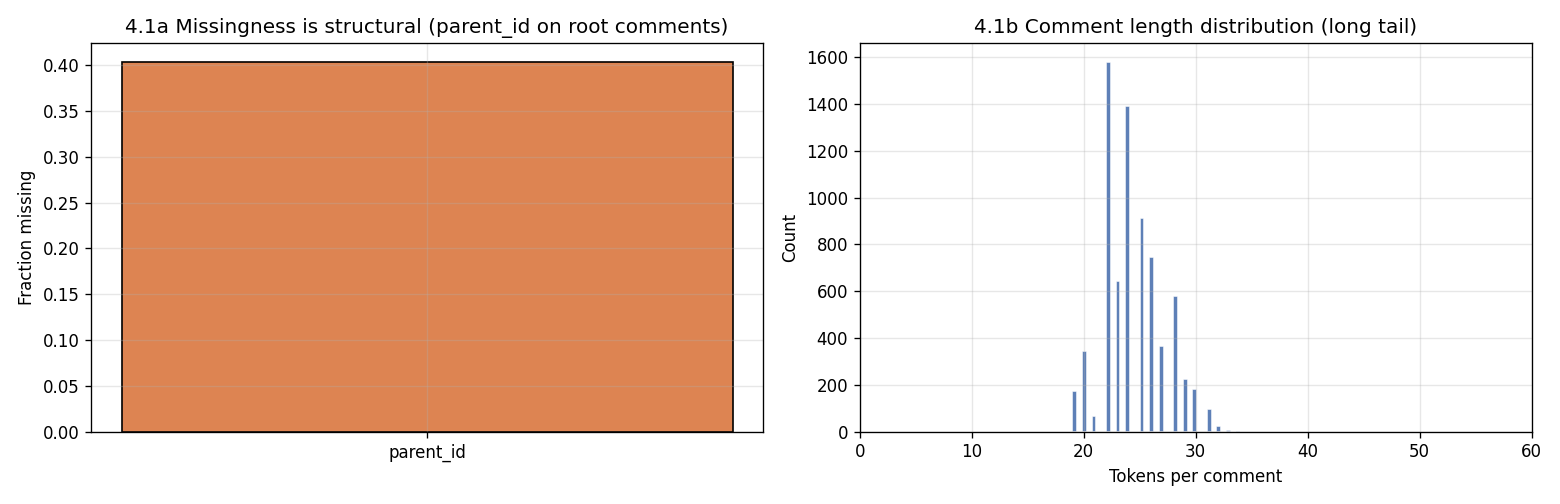

In [6]:
overview = pd.read_csv('outputs/tables/eda_overview.csv').set_index('metric')
display(overview)
display(Image('outputs/figures/fig1_integrity_and_length.png'))


### 4.2 Weak-supervision signal (`ai_confidence`)

 threshold  n_high_conf  share_high  AI_rate_high  n_low_conf  share_low  retained_total  retained_share
     0.500         3985      0.5420           1.0        3367     0.4580            7352          1.0000
     0.700         3472      0.4723           1.0        2836     0.3857            6308          0.8580
     0.850         3208      0.4363           1.0        2678     0.3643            5886          0.8006
     0.900         3057      0.4158           1.0        2671     0.3633            5728          0.7791
     0.950         2407      0.3274           1.0        2533     0.3445            4940          0.6719
     0.975         1360      0.1850           1.0        1881     0.2558            3241          0.4408
     0.990          504      0.0686           1.0         904     0.1230            1408          0.1915


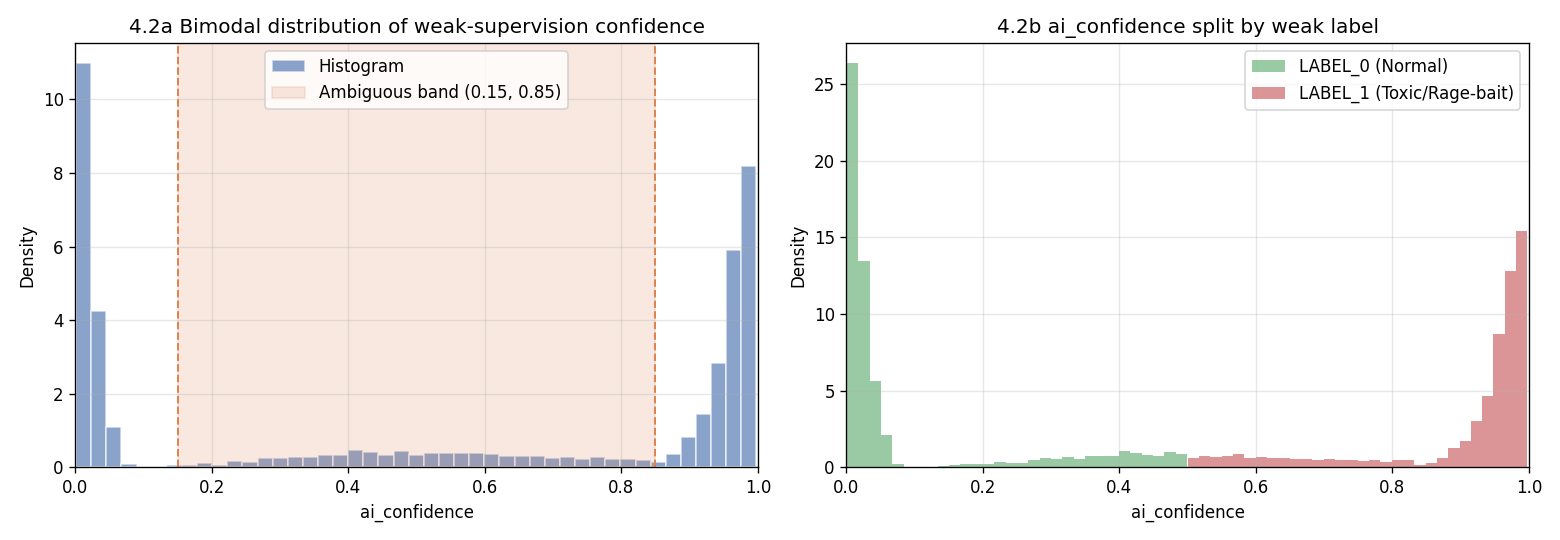

In [7]:
thresh_table = pd.read_csv('outputs/tables/threshold_summary.csv')
display(thresh_table)
display(Image('outputs/figures/fig2_weak_supervision_confidence.png'))


### 4.3 User activity and label stability

 n_users  single_comment_user_share  users_with_2_comments  two_comment_agreement_rate
    1717                     0.3419                    416                      0.8413


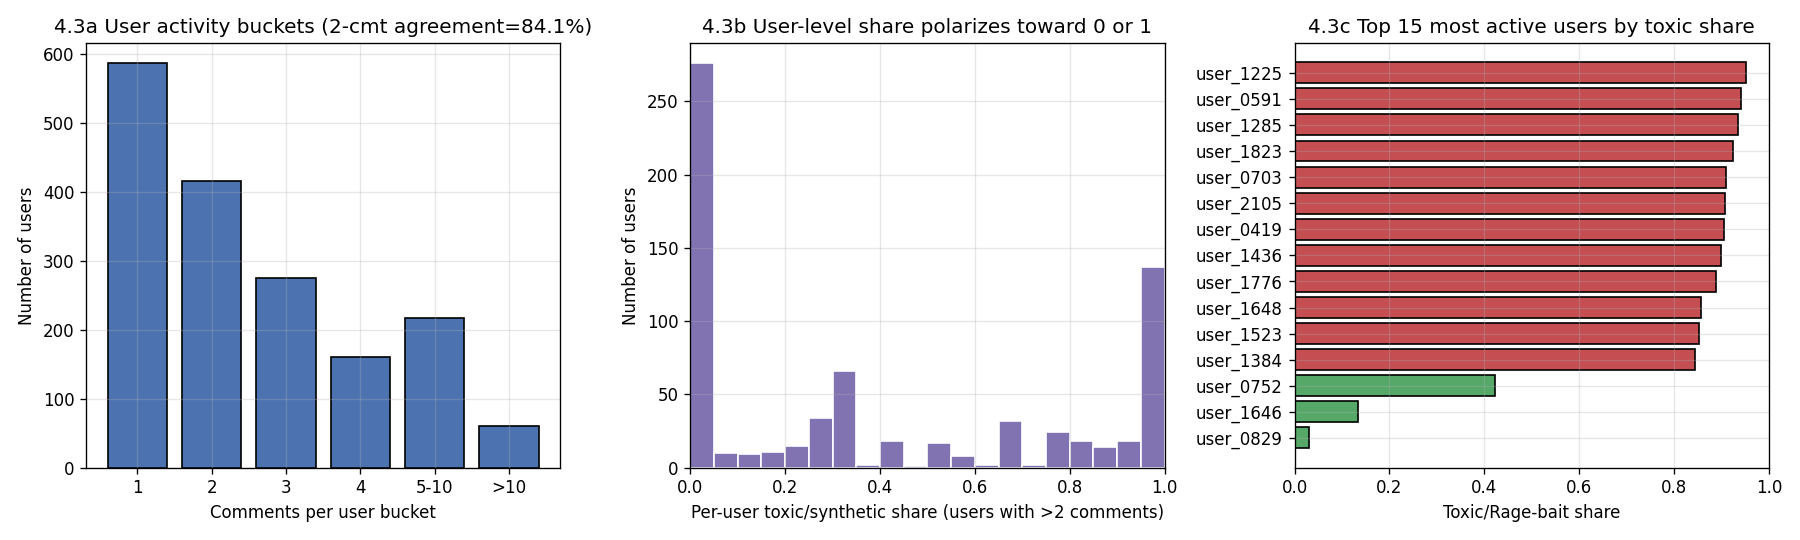

In [8]:
user_stats = pd.read_csv('outputs/tables/user_stability_stats.csv')
display(user_stats)
display(Image('outputs/figures/fig3_user_activity_and_stability.png'))


### 4.4 & 4.5 Affective signals and Rage-Bait Index ($\text{RBI}$)

              s       h       o       i     RBI
label                                          
LABEL_0  0.6871  0.0926  0.1168  0.1267  0.2006
LABEL_1 -0.5475  0.7621  0.8201  0.4335  0.7351


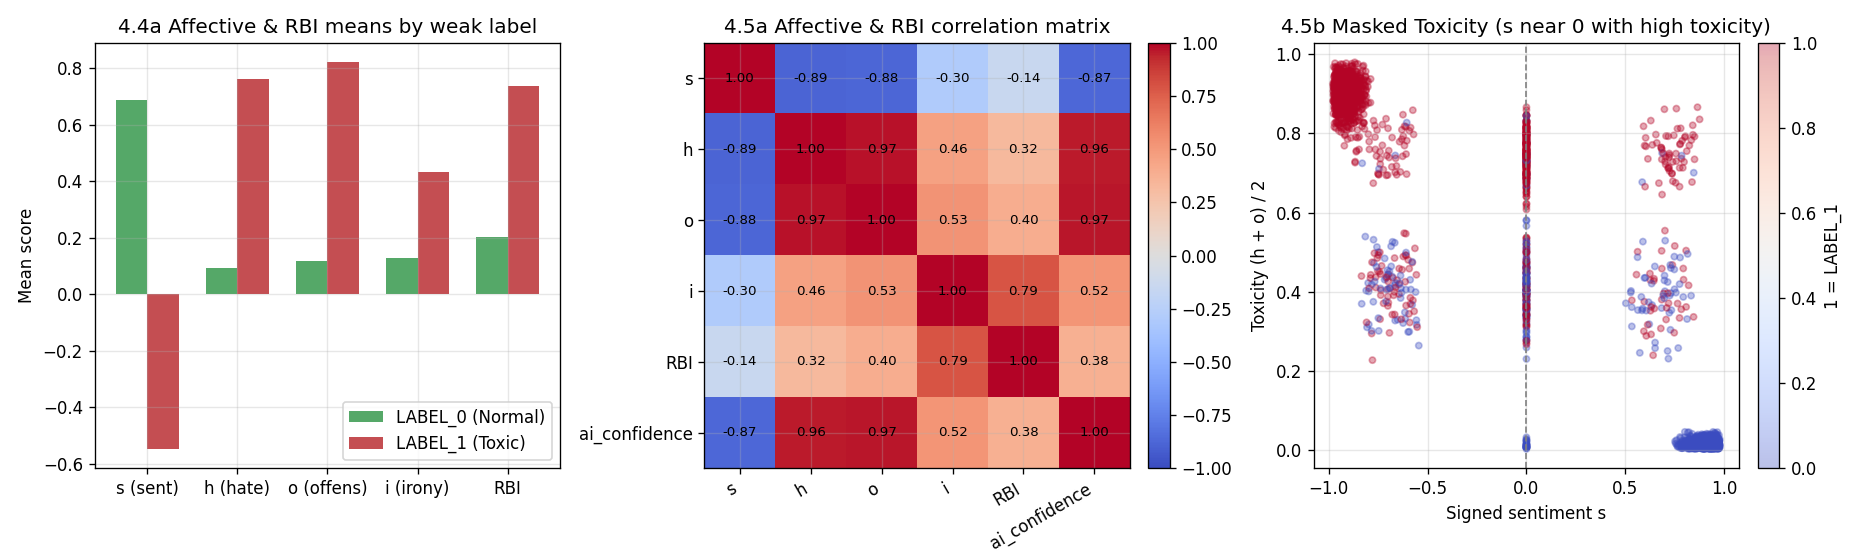

In [9]:
display(df.groupby('label')[['s', 'h', 'o', 'i', 'RBI']].mean().round(4))
display(Image('outputs/figures/fig4_affective_and_rbi.png'))


### 4.6 Embedding spaces (PCA & K-Means diagnostics)

       space  threshold  n_samples     ARI  silhouette  best_mapped_acc
PsychLexicon        0.0       2500  0.3165      0.3023           0.7816
PsychLexicon        0.7       2500  0.4059      0.3025           0.8188
PsychLexicon        0.9       2500  0.7617      0.3118           0.9364
   TFIDF_LSA        0.0       2500  0.0000      0.0896           0.5112
   TFIDF_LSA        0.7       2500  0.0541      0.0849           0.6168
   TFIDF_LSA        0.9       2500 -0.0017      0.2248           0.5136


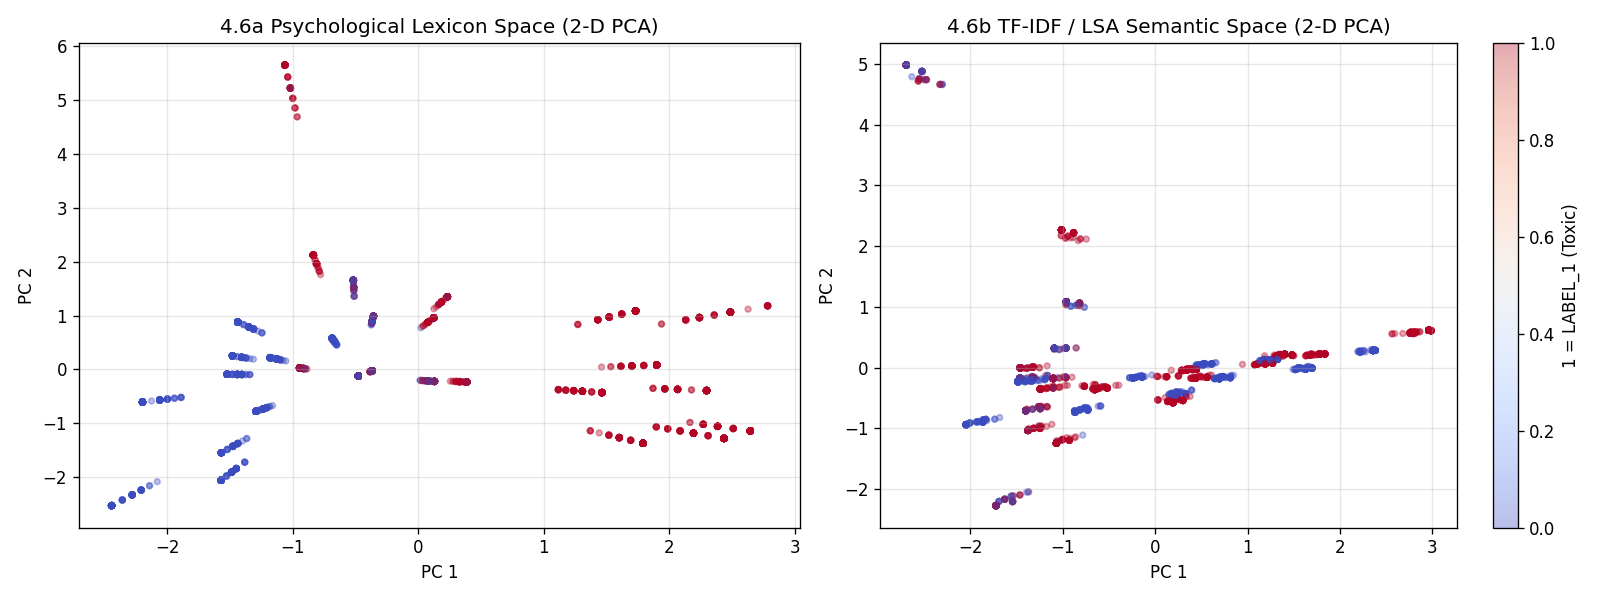

In [10]:
diag_df = pd.read_csv('outputs/tables/clustering_diagnostics.csv')
display(diag_df)
display(Image('outputs/figures/fig5_embedding_pca_spaces.png'))


## Part 5 — Baseline Modeling & Data Curation Ablation

               Dataset_Version  Threshold  Train_Rows               Model  GT_Accuracy  GT_Macro_F1  GT_ROC_AUC  HighConf_F1  HighConf_ROC_AUC
    V0: Raw Uncleaned (t=0.50)       0.50        5514 Logistic Regression       0.7171       0.7167      0.7923       0.7696            0.8459
    V0: Raw Uncleaned (t=0.50)       0.50        5514       Random Forest       0.7922       0.7917      0.8735       0.8599            0.9313
    V0: Raw Uncleaned (t=0.50)       0.50        5514   Gradient Boosting       0.7758       0.7751      0.8480       0.8391            0.9037
    V1: Cleaned + LSA (t=0.50)       0.50        5514 Logistic Regression       0.9146       0.9142      0.9710       0.9884            0.9994
    V1: Cleaned + LSA (t=0.50)       0.50        5514       Random Forest       0.9276       0.9273      0.9872       0.9986            1.0000
    V1: Cleaned + LSA (t=0.50)       0.50        5514   Gradient Boosting       0.9162       0.9157      0.9807       0.9918            0.9997

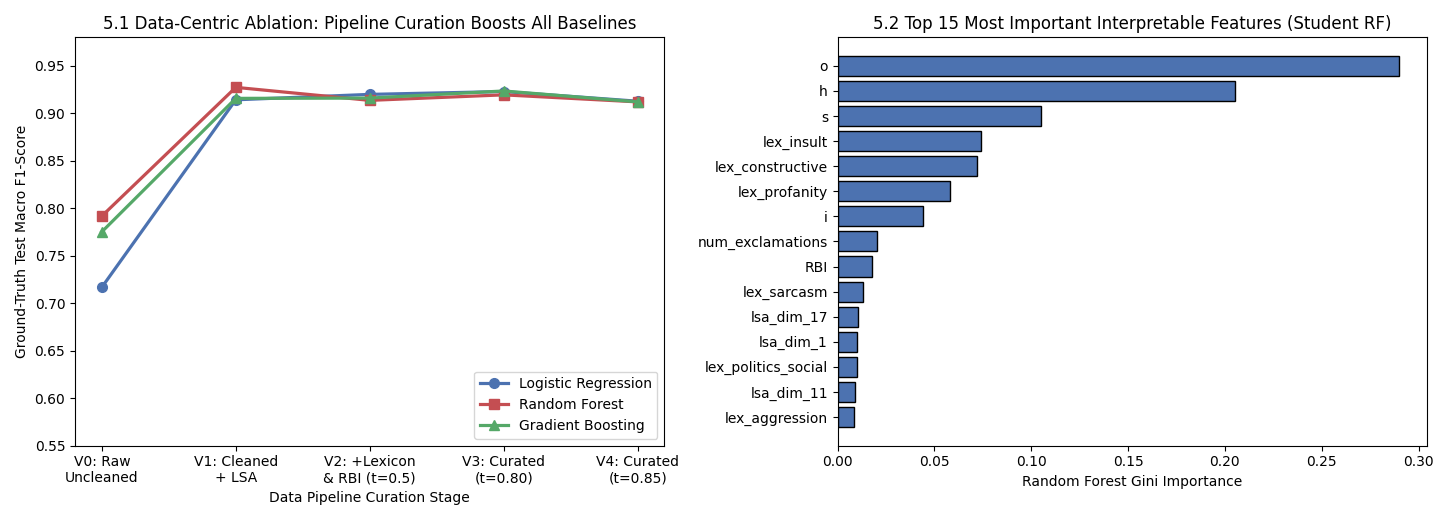

In [11]:
ablation_df = pd.read_csv('outputs/tables/ablation_benchmark.csv')
display(ablation_df)

top15_df = pd.read_csv('outputs/tables/top15_feature_importance.csv')
display(top15_df.head(10))
display(Image('outputs/figures/fig6_modeling_ablation_and_importance.png'))
